In [1]:
# Open Zsun, 0.45, 0.1 Zsun grids
from posydon.grids.psygrid import PSyGrid
from posydon.config import PATH_TO_POSYDON_DATA
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
from posydon.popsyn.distributions import PowerLawPeriod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))


grid = PSyGrid(f"{PATH_TO_POSYDON_DATA}/HMS-HMS/1e-02_Zsun.h5")

In [2]:
np.unique(grid.initial_values['star_1_mass'])

array([  3.91962324,   4.07412709,   4.23472117,   4.40164555,
         4.57514977,   4.75549318,   4.94294537,   5.13778656,
         5.34030801,   5.55081245,   5.76961457,   5.76961457,
         5.99704143,   6.23343302,   6.47914269,   6.73453776,
         7.        ,   7.27592624,   7.56272895,   7.86083686,
         8.17069559,   8.49276835,   8.82753659,   9.17550073,
         9.53718093,   9.91311785,  10.30387347,  10.71003191,
        11.13220031,  11.13220031,  11.57100977,  12.02711622,
        12.5012015 ,  12.99397429,  13.50617122,  14.03855794,
        15.76497338,  17.70369769,  19.8808399 ,  22.32571986,
        22.32571986,  25.07126308,  28.15444413,  31.61678459,
        35.50491224,  39.87118896,  44.77441597,  44.77441597,
        50.28062562,  56.46397073,  56.46397073,  63.40772318,
        63.40772318,  71.20539535,  79.96199946,  89.7954618 ,
       100.83821083, 100.83821083, 113.23896062, 127.16471363,
       142.80300971, 160.36445173, 180.08554184, 202.23

In [3]:
period_value = 2.68269580e+01 # days
M1_value = 31.61678459 # Msun
q_value = 0.9 # M2/M1
M2_value = M1_value * q_value
print(M1_value, M2_value, period_value)
print(f"Period: {period_value} days, M1: {M1_value} Msun, M2: {M2_value} Msun")

31.61678459 28.455106131 26.826958
Period: 26.826958 days, M1: 31.61678459 Msun, M2: 28.455106131 Msun


In [4]:
# in Zsun find the closest model to the given period, M1, and M2

data = grid.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# print(np.unique(Zsun_data['period_days']))
# print(np.unique(Zsun_data['star_1_mass']))
# print(np.unique(Zsun_data['star_2_mass']))


# Find the closest model in Zsun grid
P_mask = np.isclose(data['period_days'], period_value, atol=0.1)
M1_mask = np.isclose(data['star_1_mass'], M1_value, atol=1)
M2_mask = np.isclose(data['star_2_mass'], M2_value, atol=1)

model_id = np.where(P_mask & M1_mask & M2_mask)[0][0]


Primary has depleted central carbon


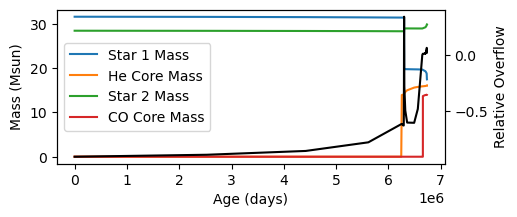

In [5]:
model = grid[model_id]


fig, ax = plt.subplots(figsize=(5, 2))
print(grid.final_values['termination_flag_1'][model_id])
ax.plot(model.binary_history['age'], model.binary_history['star_1_mass'], label='Star 1 Mass')
ax.plot(model.binary_history['age'], model.history1['he_core_mass'], label='He Core Mass')
ax.plot(model.binary_history['age'], model.binary_history['star_2_mass'], label='Star 2 Mass')
ax.plot(model.binary_history['age'], model.history1['co_core_mass'], label='CO Core Mass')

ax2 = ax.twinx()

ax2.plot(model.binary_history['age'], model.binary_history['rl_relative_overflow_1'], color='black')


ax.set_xlabel('Age (days)')
ax.set_ylabel('Mass (Msun)')
ax2.set_ylabel('Relative Overflow')
ax.legend()
plt.show()

In [6]:
model.binary_history.dtype.names

('model_number',
 'age',
 'star_1_mass',
 'star_2_mass',
 'period_days',
 'binary_separation',
 'lg_system_mdot_1',
 'lg_system_mdot_2',
 'lg_wind_mdot_1',
 'lg_wind_mdot_2',
 'lg_mstar_dot_1',
 'lg_mstar_dot_2',
 'lg_mtransfer_rate',
 'xfer_fraction',
 'rl_relative_overflow_1',
 'rl_relative_overflow_2',
 'trap_radius',
 'acc_radius',
 't_sync_rad_1',
 't_sync_conv_1',
 't_sync_rad_2',
 't_sync_conv_2')

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
from scipy.stats import gaussian_kde
from posydon.utils.common_functions import convert_metallicity_to_string
from posydon.popsyn.distributions import PowerLawPeriod

from wr_population.paths import FIGURE_DIR, EXTRA_FIGURE_DIR
from wr_population.io import load_metallicity
from wr_population.classification import (classify_WR, make_binary_mask,
                                          formation_channel_masks, CHANNEL_COLOURS)
from wr_population.plotting import METALLICITY_COLOURS, plot_period_histogram

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))
COLORS = METALLICITY_COLOURS
from wr_population.paths import DATA_DIR
from wr_population.stellar import calc_Teff, tout_L_ZAMS, tout_R_ZAMS

from wr_population.plotting import use_posydon_style
use_posydon_style()


In [8]:
# NOTE: these pickles come from the superseded run 2025_11_04
data_folder = DATA_DIR / 'optical_depth_test'
metallicities = [0.01, 0.1, 0.2, 0.45, 1.0]  # in units of Zsun

WR_data = {Z: load_metallicity(Z, data_folder) for Z in metallicities}

In [9]:
WR_data[0.2]['key']

array([    0,     0,     0, ..., 99999, 99999, 99999])

In [10]:
keys = np.unique(WR_data[0.2]['key'])

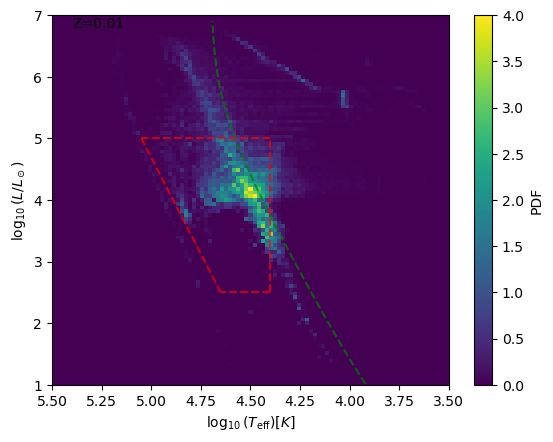

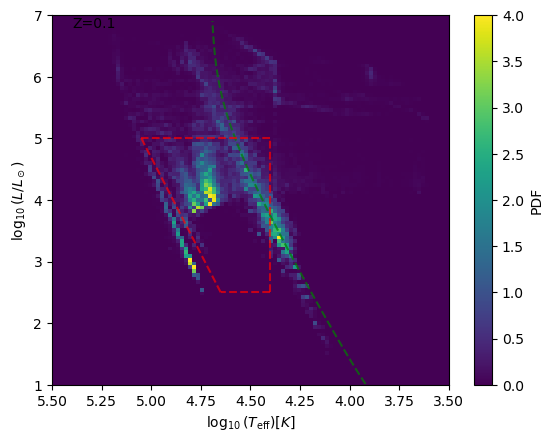

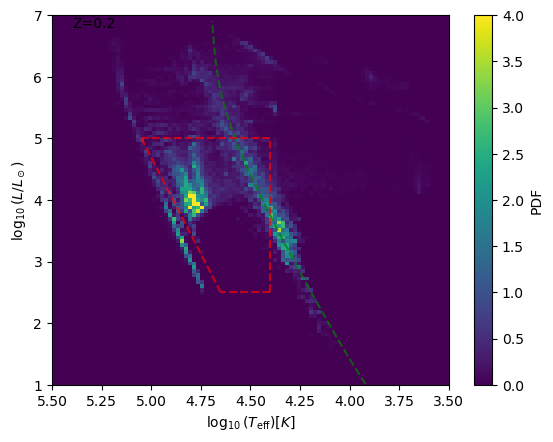

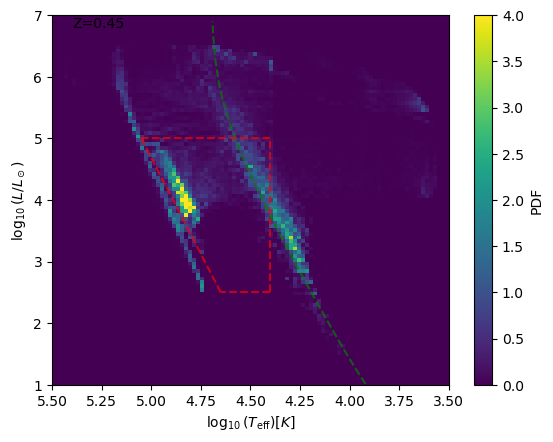

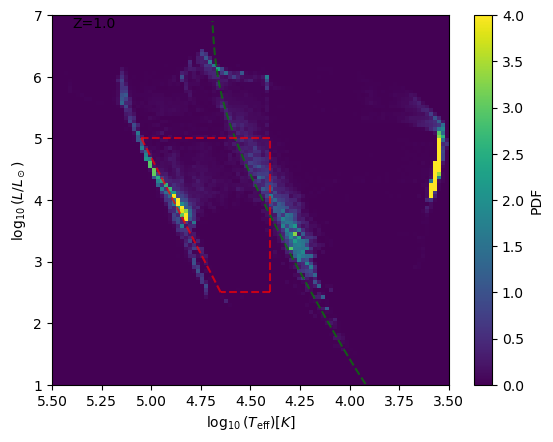

<Figure size 640x480 with 0 Axes>

In [11]:

#plt.plot(np.log10(WR_data[0.2]['Teff'][:100]), np.log10(WR_data[0.2]['L'][:100]), s=1

xbins = np.linspace(3.5, 5.5, 100)
ybins = np.linspace(1, 7, 100)
for met in metallicities:
    h, xedges, yedges = np.histogram2d(np.log10(WR_data[met]['Teff']),np.log10(WR_data[met]['L']), 
                                       weights=WR_data[met]['weight'], bins=[xbins, ybins],density=True)
    plt.imshow(h.T, origin='lower', extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]], aspect='auto', vmin=0, vmax=4)


    M_zams = np.logspace(0.08, 2.5, 100) 
    L_zams = tout_L_ZAMS(M_zams)
    R_zams = tout_R_ZAMS(M_zams)

    # # Hurley et al. (2000) for ZAMS Teff (derived from their radius formula)
    # # log(Teff) approximation for MS stars
    log_Teff_zams = calc_Teff(np.log10(L_zams), np.log10(R_zams))
    log_L_zams = np.log10(L_zams)

    plt.plot(log_Teff_zams, log_L_zams, 'g--', linewidth=1.5, label='ZAMS', alpha=0.7)
    plt.xlabel('$\log_{10}(T_\mathrm{eff}) [K]$')
    plt.ylabel('$\log_{10}(L/L_\odot)$')
    plt.xlim(5.5, 3.5)
    plt.ylim(1, 7)
    plt.text(5.4, 6.8, f'Z={met}')
    plt.plot([4.4, 4.65], [2.5, 2.5], color='red', linestyle='--', alpha=0.7)
    plt.plot([4.4, 4.4], [2.5, 5], color='red', linestyle='--', alpha=0.7)
    plt.plot([4.65, 5.05], [2.5, 5], color='red', linestyle='--', alpha=0.7)
    plt.plot([4.4, 5.05], [5, 5], color='red', linestyle='--', alpha=0.7)
    plt.colorbar(label='PDF')
    plt.show()
    plt.clf()